In [1]:
import os
import numpy as np

DATA_DIR = "/home/xugeng/experimental-methods/homework1.1/Data-Lise++"

f_dEdx_p = os.path.join(DATA_DIR, "H1EnergyLossInH2O.txt")
f_range_p = os.path.join(DATA_DIR, "H1RangeInH2O.txt")
f_dEdx_C = os.path.join(DATA_DIR, "C12EnergyLossInH2O.txt")
f_range_C = os.path.join(DATA_DIR, "C12RangeInH2O.txt")

A_p = 1.0
A_C = 12.0
R_target = 126.95  # mm

print(f"[OK] Cell 0 done. R_TARGET={R_target} mm")

[OK] Cell 0 done. R_TARGET=126.95 mm


In [2]:
def load_lise_data(filepath, pair_idx):
    try:
        with open(filepath, 'r') as f:
            lines = f.readlines()
    except FileNotFoundError:
        print(f"[FATAL] Cannot open file: {filepath}")
        return None

    data = []
    line_count = 0
    data_count = 0

    for line in lines:
        line_count += 1
        stripped = line.strip()
        if not stripped or stripped[0] in ('!', '#'):
            continue
        tokens = stripped.replace('\t', ' ').split()
        eps_col = 2 * pair_idx
        val_col = 2 * pair_idx + 1
        if val_col >= len(tokens):
            continue
        try:
            eps = float(tokens[eps_col])
            val = float(tokens[val_col])
            data.append([eps, val])
            data_count += 1
        except ValueError:
            pass

    result = np.array(data)
    print(f"[INFO] read {line_count} lines, extracted {data_count} data points (pair_idx={pair_idx})")
    return result

p_dEdx = load_lise_data(f_dEdx_p, 2)
p_range = load_lise_data(f_range_p, 2)
C_dEdx = load_lise_data(f_dEdx_C, 2)
C_range = load_lise_data(f_range_C, 2)

print("\n========== 数据诊断 ==========")
print(f"p_dEdx: {len(p_dEdx)} pts, first eps={p_dEdx[0,0]:.4f}, first val={p_dEdx[0,1]:.4f}")
print(f"p_range: {len(p_range)} pts, first eps={p_range[0,0]:.4f}, first val={p_range[0,1]:.4f}")
print(f"C_dEdx: {len(C_dEdx)} pts, first eps={C_dEdx[0,0]:.4f}, first val={C_dEdx[0,1]:.4f}")
print(f"C_range: {len(C_range)} pts, first eps={C_range[0,0]:.4f}, first val={C_range[0,1]:.4f}")

[INFO] read 271 lines, extracted 268 data points (pair_idx=2)
[INFO] read 271 lines, extracted 268 data points (pair_idx=2)
[INFO] read 271 lines, extracted 268 data points (pair_idx=2)
[INFO] read 271 lines, extracted 268 data points (pair_idx=2)

========== 数据诊断 ==========
p_dEdx: 268 pts, first eps=0.0010, first val=0.2169
p_range: 268 pts, first eps=0.0010, first val=0.0042
C_dEdx: 268 pts, first eps=0.0010, first val=1.5011
C_range: 268 pts, first eps=0.0010, first val=0.0078


In [3]:
# 单位转换
p_range[:, 1] /= 100.0
C_range[:, 1] /= 100.0
p_dEdx[:, 1] *= 100.0
C_dEdx[:, 1] *= 100.0

# 排序
p_range = p_range[p_range[:, 0].argsort()]
C_range = C_range[C_range[:, 0].argsort()]
p_dEdx = p_dEdx[p_dEdx[:, 0].argsort()]
C_dEdx = C_dEdx[C_dEdx[:, 0].argsort()]

# 线性插值函数（边界外返回 NaN）
def make_interp(x, y):
    def interp(xq):
        xq = np.asarray(xq, dtype=float)
        # 向量化边界检查
        mask = (xq >= x[0]) & (xq <= x[-1])
        result = np.full_like(xq, np.nan, dtype=float)
        result[mask] = np.interp(xq[mask], x, y)
        # 标量输入返回标量
        return float(result) if xq.ndim == 0 else result
    return interp

R_of_eps_p = make_interp(p_range[:, 0], p_range[:, 1])
eps_of_R_p = make_interp(p_range[:, 1], p_range[:, 0])
S_of_eps_p = make_interp(p_dEdx[:, 0], p_dEdx[:, 1])

R_of_eps_C = make_interp(C_range[:, 0], C_range[:, 1])
eps_of_R_C = make_interp(C_range[:, 1], C_range[:, 0])
S_of_eps_C = make_interp(C_dEdx[:, 0], C_dEdx[:, 1])

# 标定入射能量
eps0_p = eps_of_R_p(R_target)
eps0_C = eps_of_R_C(R_target)

if np.isnan(eps0_p) or np.isnan(eps0_C):
    print("[ERROR] R_target out of range!")
    print(f"p_range R max = {p_range[:,1].max():.4f}, C_range R max = {C_range[:,1].max():.4f}")
else:
    E0_p = A_p * eps0_p
    E0_C = A_C * eps0_C
    R_check_p = R_of_eps_p(eps0_p)
    R_check_C = R_of_eps_C(eps0_C)

    print("\n========== 入射能量标定 ==========")
    print(f"Proton : eps0={eps0_p:.4f} MeV/u, E0={E0_p:.4f} MeV, R(eps0)={R_check_p:.4f} mm")
    print(f"C12    : eps0={eps0_C:.4f} MeV/u, E0={E0_C:.4f} MeV, R(eps0)={R_check_C:.4f} mm")

    if abs(R_check_p - R_target) > 0.5 or abs(R_check_C - R_target) > 0.5:
        print("[WARNING] 射程校验偏差 > 0.5 mm")


========== 入射能量标定 ==========
Proton : eps0=132.4555 MeV/u, E0=132.4555 MeV, R(eps0)=126.9500 mm
C12    : eps0=251.9653 MeV/u, E0=3023.5837 MeV, R(eps0)=126.9500 mm


In [4]:
import math

def compute_bragg(S_of_eps, eps0, A, max_depth=150.0, dx=0.005):
    x_list, dEdx_list, eps_list = [], [], []
    x = 0.0
    eps = eps0

    while x < max_depth and eps > 0:
        # 保护1：防止 S 过大导致一步跳过头
        S = S_of_eps(eps)
        if not math.isfinite(S):
            break
            
        # 保护2：限制每一步能量损失不超过当前能量的 5%，确保不越过终点
        deps_raw = S * dx / A
        if deps_raw > eps * 0.05:
            deps = eps * 0.05  # 如果步长太大，则缩小步长
        else:
            deps = deps_raw
            
        # 精确停在终点 (防止 eps 变成负数)
        if eps - deps <= 0:
            deps = eps  # 最后一步刚好用完剩余能量
            
        actual_dx = deps * A / S
        
        x += actual_dx
        eps -= deps
        
        x_list.append(x)
        dEdx_list.append(S)
        eps_list.append(eps)
        
        if len(x_list) > 50000:
            print("[WARN] Reached max points limit")
            break

    print(f"[OK] Bragg curve computed: {len(x_list)} points (final x={x:.4f}, eps={eps:.6f})")
    return np.array(x_list), np.array(dEdx_list), np.array(eps_list)

# 重新计算 (使用 0.005 步长)
x_p, dEdx_p, eps_p = compute_bragg(S_of_eps_p, eps0_p, A_p, dx=0.005)
x_C, dEdx_C, eps_C = compute_bragg(S_of_eps_C, eps0_C, A_C, dx=0.005)

[OK] Bragg curve computed: 25326 points (final x=125.9595, eps=0.000969)
[OK] Bragg curve computed: 25533 points (final x=126.9475, eps=0.000966)


In [5]:
# ========== 验算 Cell ==========
print("\n========== 射程闭环验算 ==========")

# 1. 标定能量
print(f"标定值: Proton eps0={eps0_p:.4f} MeV/u, C12 eps0={eps0_C:.4f} MeV/u")

# 2. 将标定能量代入能量-射程函数 R(eps)
R_calc_p = R_of_eps_p(eps0_p)
R_calc_C = R_of_eps_C(eps0_C)

# 3. 计算偏差
delta_p = abs(R_calc_p - R_target)
delta_C = abs(R_calc_C - R_target)

print(f"Proton : R({eps0_p:.4f}) = {R_calc_p:.4f} mm, 目标={R_target} mm, 偏差={delta_p:.4f} mm")
print(f"C12    : R({eps0_C:.4f}) = {R_calc_C:.4f} mm, 目标={R_target} mm, 偏差={delta_C:.4f} mm")

if delta_p < 0.1 and delta_C < 0.1:
    print("[OK] 验算通过！标定的能量恰好对应 127 mm 射程。")
else:
    print("[WARNING] 验算偏差较大，请检查插值范围。")


========== 射程闭环验算 ==========
标定值: Proton eps0=132.4555 MeV/u, C12 eps0=251.9653 MeV/u
Proton : R(132.4555) = 126.9500 mm, 目标=126.95 mm, 偏差=0.0000 mm
C12    : R(251.9653) = 126.9500 mm, 目标=126.95 mm, 偏差=0.0000 mm
[OK] 验算通过！标定的能量恰好对应 127 mm 射程。


[INFO] x_plot: 1699 points, 末端相邻间距 0.000 um (最后 5 um 内有 759 点)
[INFO] 阻止本领峰值: S = 859.63 MeV/mm
[INFO] S(x=0.01 mm): proton 0.5979, C12 14.1613 MeV/mm
[OK] Fig1 generated.
[INFO] zoom: kept 1088/1089 (proton), 991/1089 (C12); C12 峰值 859.63 MeV/mm，末端 150.14 MeV/mm
[OK] Fig2 generated.


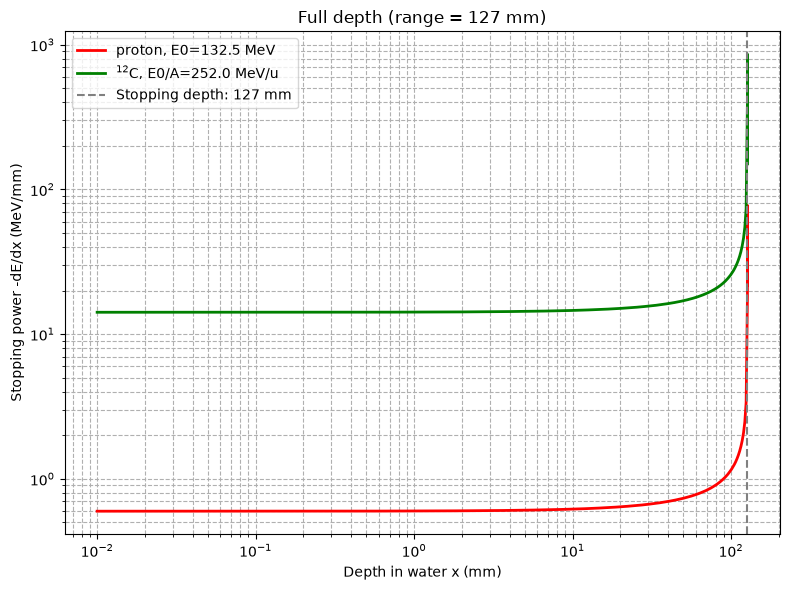

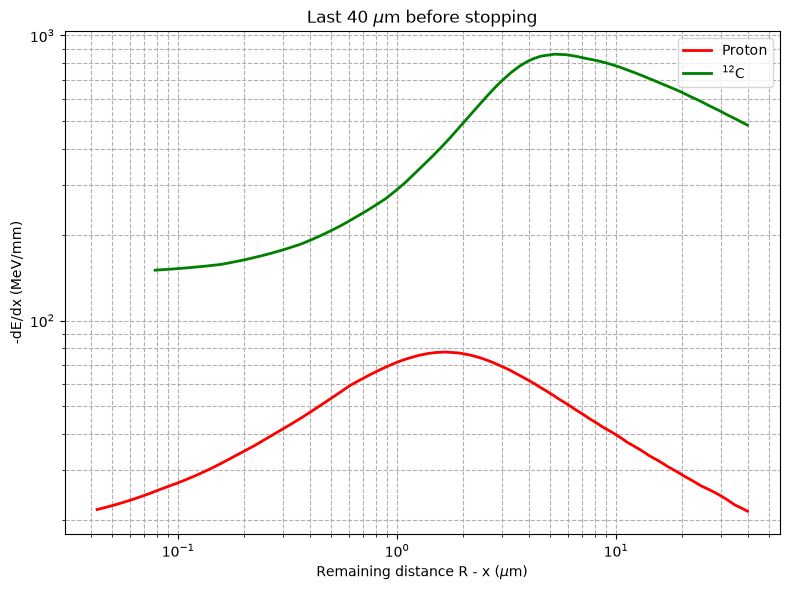

In [6]:
# ========== Cell A: 剩余射程法绘图 (Section 3) ==========
import matplotlib.pyplot as plt

# ---------------------------------------------------------------------------
# 【修复 1】这里原来用的是 R_of_eps_p(r)，但 R_of_eps_p 是"能量 -> 射程"的插值；
# 把以 mm 为单位的剩余射程当成能量喂进射程表，数值完全不对（例：r = 0.05 mm 时得到
# eps = 0.00099 MeV/u，正确值是 1.56 MeV/u），整条 S(x) 都是错的。
# 剩余射程 -> 每核子能量必须用反函数 eps_of_R_*。
#
# 【修复 2】深度取样。原来 x_plot = np.logspace(-2, log10(R_target), 500) 在 127 mm
# 附近点距约 2.4 mm，截取"最后 40 μm"时只剩 1 个点，放大图只有坐标轴。
# 注意：阻止本领的峰值出现在 eps ≈ 0.25 MeV/u，对应剩余射程只有 ~5.2 μm，
# 所以峰值和峰后下降端全部挤在最后 5 μm 里；末端必须按"剩余射程等比"取样
# （而不是在 40 μm 内均匀取样），才能把下降端画出来。
# ---------------------------------------------------------------------------

# 1. 生成深度数组：主体与原代码一致（0.01 mm 起，500 点），末端按剩余射程等比加密
x_main = np.logspace(-2, np.log10(R_target - 0.08), 500)          # 原 500 点的前 80 μm 之外部分
r_tail = np.geomspace(0.08, min(p_range[:, 1].min(), C_range[:, 1].min()), 1200)
x_plot = np.unique(np.concatenate([x_main, R_target - r_tail]))
print(f"[INFO] x_plot: {len(x_plot)} points, 末端相邻间距 {np.diff(x_plot)[-1]*1000:.3f} um "
      f"(最后 5 um 内有 {int((x_plot > R_target - 0.005).sum())} 点)")
print(f"[INFO] 阻止本领峰值: S = {np.nanmax(S_of_eps_C(eps_of_R_C(R_target - x_plot))):.2f} MeV/mm")

# 计算剩余射程和能量（用反函数！）
r_p = R_target - x_plot
eps_p_map = eps_of_R_p(r_p)      # 修复：射程 -> 能量，用反函数（原来是 R_of_eps_p）
S_p_map = S_of_eps_p(eps_p_map)

r_C = R_target - x_plot
eps_C_map = eps_of_R_C(r_C)      # 修复：同上
S_C_map = S_of_eps_C(eps_C_map)

print(f"[INFO] S(x=0.01 mm): proton {S_p_map[0]:.4f}, C12 {S_C_map[0]:.4f} MeV/mm")

# 图1: 双对数坐标主图
fig1, ax1 = plt.subplots(figsize=(8, 6))
ax1.loglog(x_plot, S_p_map, 'r-', linewidth=2, label=f'proton, E0={eps0_p:.1f} MeV')
ax1.loglog(x_plot, S_C_map, 'g-', linewidth=2, label=f'$^{{12}}$C, E0/A={eps0_C:.1f} MeV/u')

# 添加参考线
ax1.axvline(R_target, color='gray', linestyle='--', linewidth=1.5, label=f'Stopping depth: {R_target:.0f} mm')

ax1.set_xlabel('Depth in water x (mm)')
ax1.set_ylabel('Stopping power -dE/dx (MeV/mm)')
ax1.set_title('Full depth (range = 127 mm)')
ax1.legend(loc='upper left')
ax1.grid(True, which="both", ls="--")
fig1.tight_layout()
# plt.savefig('Fig1_Bragg_loglog.png')  # 已按要求注释掉
print("[OK] Fig1 generated.")

# 图2: 峰后放大图 (最后 40 μm)
fig2, ax2 = plt.subplots(figsize=(8, 6))

# 修正：截取最后 40 μm (0.04 mm)
mask_p = (x_plot > R_target - 0.04)
mask_C = (x_plot > R_target - 0.04)

# 计算剩余距离（单位 μm）
remain_p = (R_target - x_plot[mask_p]) * 1000
remain_C = (R_target - x_plot[mask_C]) * 1000

# 数据表的能量下限是 0.001 MeV/u，射程反函数在最末端会给出低于该下限的 eps，
# 此时 S(eps) 落在表外（NaN）。必须先用 isfinite 过滤掉，否则 matplotlib
# 会因为序列里的 NaN 把整条线都丢掉（这就是"只有坐标轴"的另一个原因）。
valid_p = np.isfinite(S_p_map[mask_p])
valid_C = np.isfinite(S_C_map[mask_C])
print(f"[INFO] zoom: kept {valid_p.sum()}/{mask_p.sum()} (proton), "
      f"{valid_C.sum()}/{mask_C.sum()} (C12); "
      f"C12 峰值 {S_C_map[mask_C][valid_C].max():.2f} MeV/mm，末端 {S_C_map[mask_C][valid_C][-1]:.2f} MeV/mm")

ax2.loglog(remain_p[valid_p], S_p_map[mask_p][valid_p], 'r-', linewidth=2, label='Proton')
ax2.loglog(remain_C[valid_C], S_C_map[mask_C][valid_C], 'g-', linewidth=2, label='$^{12}$C')

ax2.set_xlabel(r'Remaining distance R - x ($\mu$m)')
ax2.set_ylabel('-dE/dx (MeV/mm)')
ax2.set_title(r'Last 40 $\mu$m before stopping')
ax2.legend()
ax2.grid(True, which="both", ls="--")
fig2.tight_layout()
# plt.savefig('Fig2_PeakTail.png')  # 已按要求注释掉
print("[OK] Fig2 generated.")

plt.show()

[OK] Bragg curve computed: 25326 points (final x=125.9595, eps=0.000969)
[OK] Bragg curve computed: 25533 points (final x=126.9475, eps=0.000966)
[INFO] position-step curve: dx=0.005 mm, proton 25326 pts (stop 125.9595 mm), C12 25533 pts (stop 126.9475 mm)
[OK] Fig1 saved.
[INFO] zoom points: proton 142/142, C12 150/150
[INFO] proton: S = 20.82 ... 77.48 MeV/mm, remaining 0.00 ... 39.2 um
[INFO] C12   : S = 150.23 ... 859.06 MeV/mm, remaining 0.00 ... 38.8 um
[OK] Fig2 saved.


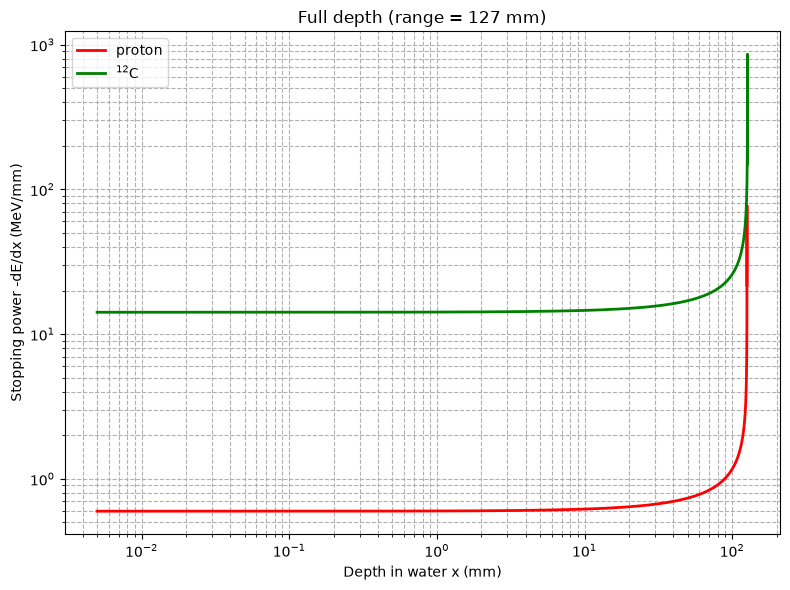

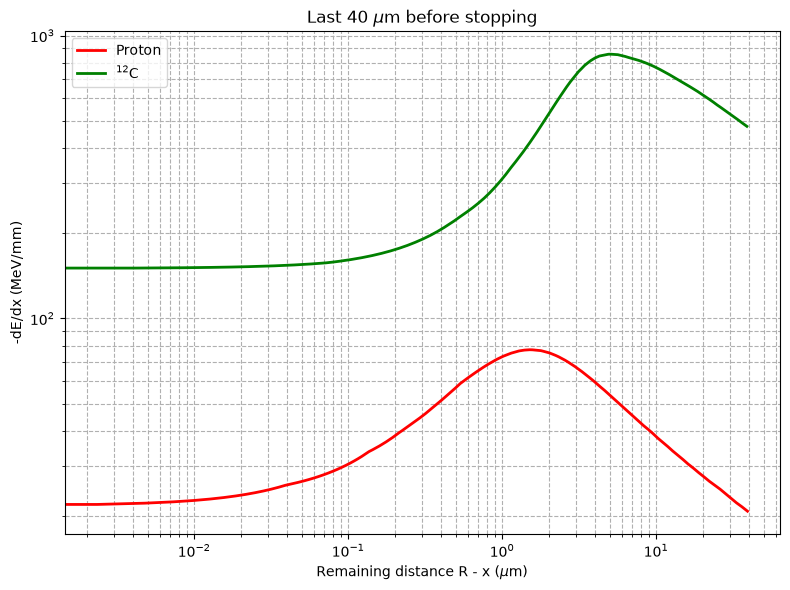

In [7]:
#固定位置步长法
import matplotlib.pyplot as plt

# 【为什么之前放大图会空】
# 这个 cell 用的 x_p / dEdx_p 是 cell 3 里 compute_bragg(..., dx=0.005) 算出来的。
# 如果 cell 3 没先运行（或用的是 dx=0.001、命中 50000 点上限只积到 50 mm 的旧结果），
# mask_p = (x_p > max_x_p - 0.04) 就会取到空/退化的数据，放大图只剩坐标轴。
# 这里改成由 cell 3 的函数就地重算，保证不依赖内核里的旧变量。

DX = 0.005                                    # 位置步长 (mm)，与 cell 3 一致
x_p, dEdx_p, eps_p = compute_bragg(S_of_eps_p, eps0_p, A_p, dx=DX)
x_C, dEdx_C, eps_C = compute_bragg(S_of_eps_C, eps0_C, A_C, dx=DX)
print(f"[INFO] position-step curve: dx={DX} mm, proton {len(x_p)} pts (stop {x_p.max():.4f} mm), "
      f"C12 {len(x_C)} pts (stop {x_C.max():.4f} mm)")

# 图1: 双对数坐标主图
fig1, ax1 = plt.subplots(figsize=(8, 6))
ax1.loglog(x_p, dEdx_p, 'r-', linewidth=2, label='proton')
ax1.loglog(x_C, dEdx_C, 'g-', linewidth=2, label='$^{12}$C')
ax1.set_xlabel('Depth in water x (mm)')
ax1.set_ylabel('Stopping power -dE/dx (MeV/mm)')
ax1.set_title('Full depth (range = 127 mm)')
ax1.legend()
ax1.grid(True, which="both", ls="--")
fig1.tight_layout()
fig1.savefig('Fig1_Bragg_loglog.png')
print("[OK] Fig1 saved.")

# 图2: 峰后放大图 (双对数坐标)
fig2, ax2 = plt.subplots(figsize=(8, 6))

max_x_p = x_p.max()
max_x_C = x_C.max()

# 截取最后 40 μm (0.04 mm)
mask_p = (x_p > max_x_p - 0.04)
mask_C = (x_C > max_x_C - 0.04)

# 横轴转换为剩余距离 R - x (单位 μm)
x_p_remain = (max_x_p - x_p[mask_p]) * 1000
x_C_remain = (max_x_C - x_C[mask_C]) * 1000

# 丢掉 NaN/非有限值：阻止本领表在 eps < 0.001 MeV/u 处没有数据，
# 序列里只要混进一个 NaN，matplotlib 会把整条线都丢掉（放大图变空的主因之一）。
ok_p = np.isfinite(dEdx_p[mask_p]) & np.isfinite(x_p_remain)
ok_C = np.isfinite(dEdx_C[mask_C]) & np.isfinite(x_C_remain)
print(f"[INFO] zoom points: proton {int(ok_p.sum())}/{int(mask_p.sum())}, "
      f"C12 {int(ok_C.sum())}/{int(mask_C.sum())}")
if ok_p.sum():
    print(f"[INFO] proton: S = {dEdx_p[mask_p][ok_p].min():.2f} ... {dEdx_p[mask_p][ok_p].max():.2f} MeV/mm, "
          f"remaining {x_p_remain[ok_p].min():.2f} ... {x_p_remain[ok_p].max():.1f} um")
if ok_C.sum():
    print(f"[INFO] C12   : S = {dEdx_C[mask_C][ok_C].min():.2f} ... {dEdx_C[mask_C][ok_C].max():.2f} MeV/mm, "
          f"remaining {x_C_remain[ok_C].min():.2f} ... {x_C_remain[ok_C].max():.1f} um")

ax2.loglog(x_p_remain[ok_p], dEdx_p[mask_p][ok_p], 'r-', linewidth=2, label='Proton')
ax2.loglog(x_C_remain[ok_C], dEdx_C[mask_C][ok_C], 'g-', linewidth=2, label='$^{12}$C')

# 加了 r 消除 SyntaxWarning
ax2.set_xlabel(r'Remaining distance R - x ($\mu$m)')
ax2.set_ylabel('-dE/dx (MeV/mm)')
ax2.set_title(r'Last 40 $\mu$m before stopping')
ax2.legend()
ax2.grid(True, which="both", ls="--")
fig2.tight_layout()
fig2.savefig('Fig2_PeakTail.png')
print("[OK] Fig2 saved.")

plt.show()

In [8]:
def compute_fixed_x(E0, A, S_func, dx=0.001):
    x, E = 0.0, E0 * A
    data = []
    while E > 0:
        eps = E / A
        S = S_func(eps)
        data.append((x, S))
        
        # 核心：防止最后一步能量过冲变负
        if S * dx > E:
            break  # 或在有效数据范围末端停止
            
        x += dx
        E -= S * dx
        
    return np.array(data)

print("计算固定位置步长...")
data_p_x = compute_fixed_x(eps0_p, A_p, S_of_eps_p, dx=0.001)
data_C_x = compute_fixed_x(eps0_C, A_C, S_of_eps_C, dx=0.001)
print(f"12C 停止深度 (固定x): {data_C_x[-1, 0]:.4f} mm")

计算固定位置步长...
12C 停止深度 (固定x): 126.9390 mm


In [9]:
def compute_fixed_E(eps0, A, S_func, d_eps=0.01):
    x, eps = 0.0, eps0
    data = []
    while eps > 0:
        S = S_func(eps)
        data.append((x, S))
        
        # 核心：最后一步确保不超过当前能量
        step_d_eps = min(d_eps, eps)
        
        dx = (A * step_d_eps) / S
        x += dx
        eps -= step_d_eps
        
    return np.array(data)

print("计算固定能量步长...")
data_p_E = compute_fixed_E(eps0_p, A_p, S_of_eps_p, d_eps=0.01)
data_C_E = compute_fixed_E(eps0_C, A_C, S_of_eps_C, d_eps=0.01)
print(f"12C 停止深度 (固定E): {data_C_E[-1, 0]:.4f} mm")

计算固定能量步长...
12C 停止深度 (固定E): 126.9421 mm


    -> 画入 delta_eps= 1.000 MeV/u:     252 点, 停止深度 127.3384 mm
    -> 画入 delta_eps= 0.300 MeV/u:     840 点, 停止深度 127.0581 mm
    -> 画入 delta_eps= 0.100 MeV/u:    2520 点, 停止深度 126.9777 mm
    -> 画入 delta_eps= 0.030 MeV/u:    8399 点, 停止深度 126.9495 mm
    -> 画入 delta_eps= 0.010 MeV/u:   25197 点, 停止深度 126.9421 mm
    -> 画入 delta_eps= 0.003 MeV/u:   83989 点, 停止深度 126.9396 mm


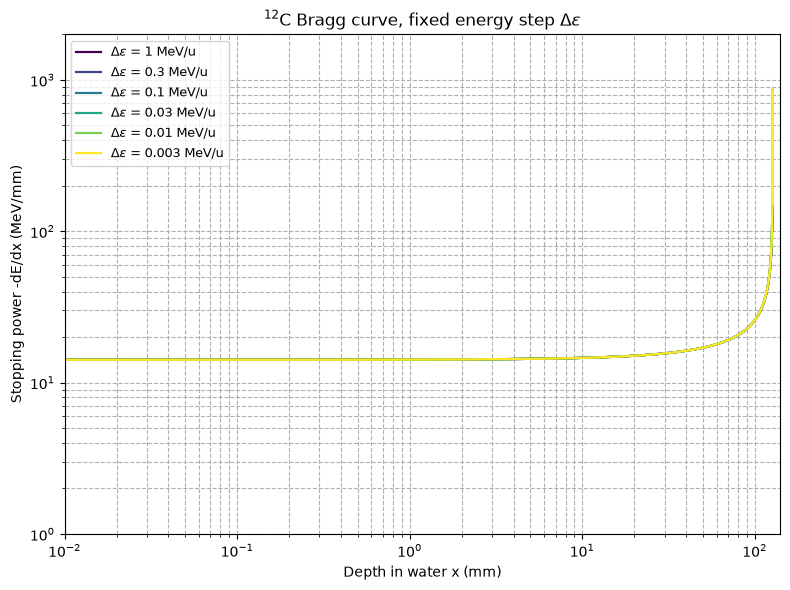

In [10]:
# ================= 4.2 固定能量步长法：不同 Δε 的曲线 =================
# 直接调用 cell 9 的 compute_fixed_E，只是对不同步长各画一条曲线，
# 观察"逐步减小能量步长"时停止深度和峰形怎么变化。
import matplotlib.pyplot as plt

DEPS_LIST = [1.0, 0.3, 0.1, 0.03, 0.01, 0.003]        # MeV/u，逐步减小
cmap = plt.get_cmap('viridis')
colors = [cmap(i / max(len(DEPS_LIST) - 1, 1)) for i in range(len(DEPS_LIST))]

fig_E, ax_E = plt.subplots(figsize=(8, 6))
for k, deps in enumerate(DEPS_LIST):
    dataE = compute_fixed_E(eps0_C, A_C, S_of_eps_C, d_eps=deps)
    xE, SE = dataE[:, 0], dataE[:, 1]
    ax_E.loglog(xE, SE, '-', color=colors[k], linewidth=1.6,
                label=rf'$\Delta\varepsilon$ = {deps:g} MeV/u')
    print(f"    -> 画入 delta_eps={deps:6.3f} MeV/u: {len(xE):7d} 点, 停止深度 {xE.max():.4f} mm")

ax_E.set_xlabel('Depth in water x (mm)')
ax_E.set_ylabel('Stopping power -dE/dx (MeV/mm)')
ax_E.set_title(r'$^{12}$C Bragg curve, fixed energy step $\Delta\varepsilon$')
ax_E.legend(fontsize=9)
ax_E.grid(True, which="both", ls="--")
ax_E.set_xlim(1e-2, 140)
ax_E.set_ylim(1, 2000)
fig_E.tight_layout()
plt.show()

=== 12C 停止深度对比 ===
  剩余射程法 (CSDA)       : 126.9500 mm   (基准)
  位置步长 dx = 0.005 mm  : 126.9450 mm
  位置步长 dx = 0.0005 mm : 126.9390 mm
  能量步长 1.0  MeV/u     : 127.3384 mm
  能量步长 0.01 MeV/u     : 126.9421 mm


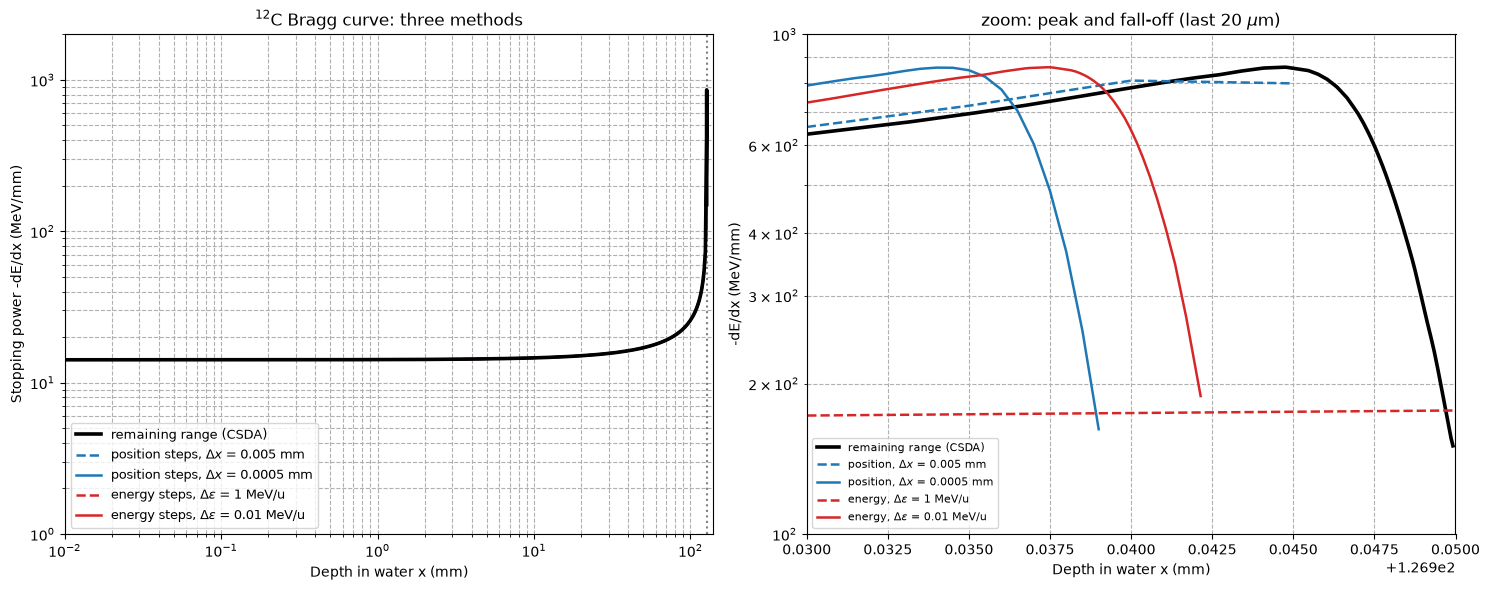

In [11]:
# ================= 4.3 三种方法比较（以 12C 为例）=================
# 1) 剩余射程法（CSDA 精确解）：cell 5 算好的 x_plot / S_C_map
# 2) 固定位置步长法：粗 dx = 0.005 mm，细 dx = 0.0005 mm
# 3) 固定能量步长法：粗 1 MeV/u，细 0.01 MeV/u
# 说明：cell 3 / cell 9 里的 50000 点上限会让细步长还没走到 127 mm 就被截断，
# 所以这里用同样的积分公式、仅去掉该上限，保证对比公平（公式与前面完全一致）。
import matplotlib.pyplot as plt

def fixed_x_curve(eps0, A, S_func, dx):
    x, E = 0.0, A * eps0
    xs, Ss = [], []
    while E > 0:
        eps = E / A
        S = S_func(eps)
        if not np.isfinite(S):
            break
        xs.append(x); Ss.append(S)
        if S * dx > E:
            break
        x += dx
        E -= S * dx
    return np.array(xs), np.array(Ss)

def fixed_E_curve(eps0, A, S_func, d_eps):
    x, eps = 0.0, eps0
    xs, Ss = [], []
    while eps > 0:
        S = S_func(eps)
        if not np.isfinite(S):
            break
        xs.append(x); Ss.append(S)
        step = min(d_eps, eps)
        x += A * step / S
        eps -= step
    return np.array(xs), np.array(Ss)

x_pos_c, S_pos_c = fixed_x_curve(eps0_C, A_C, S_of_eps_C, dx=0.005)
x_pos_f, S_pos_f = fixed_x_curve(eps0_C, A_C, S_of_eps_C, dx=0.0005)
x_en_c,  S_en_c  = fixed_E_curve(eps0_C, A_C, S_of_eps_C, d_eps=1.0)
x_en_f,  S_en_f  = fixed_E_curve(eps0_C, A_C, S_of_eps_C, d_eps=0.01)

print("=== 12C 停止深度对比 ===")
print(f"  剩余射程法 (CSDA)       : {R_target:.4f} mm   (基准)")
print(f"  位置步长 dx = 0.005 mm  : {x_pos_c[-1]:.4f} mm")
print(f"  位置步长 dx = 0.0005 mm : {x_pos_f[-1]:.4f} mm")
print(f"  能量步长 1.0  MeV/u     : {x_en_c[-1]:.4f} mm")
print(f"  能量步长 0.01 MeV/u     : {x_en_f[-1]:.4f} mm")

fig_cmp, (ax_cmp, ax_zoom) = plt.subplots(1, 2, figsize=(15, 6))

# ---------- 左：全深度 ----------
ax_cmp.loglog(x_plot, S_C_map, 'k-', linewidth=2.6, label='remaining range (CSDA)', zorder=6)
ax_cmp.loglog(x_pos_c, S_pos_c, '--', color='tab:blue', linewidth=1.8,
              label=r'position steps, $\Delta x$ = 0.005 mm')
ax_cmp.loglog(x_pos_f, S_pos_f, '-',  color='tab:blue', linewidth=1.8,
              label=r'position steps, $\Delta x$ = 0.0005 mm')
ax_cmp.loglog(x_en_c,  S_en_c,  '--', color='tab:red',  linewidth=1.8,
              label=r'energy steps, $\Delta\varepsilon$ = 1 MeV/u')
ax_cmp.loglog(x_en_f,  S_en_f,  '-',  color='tab:red',  linewidth=1.8,
              label=r'energy steps, $\Delta\varepsilon$ = 0.01 MeV/u')
ax_cmp.axvline(R_target, color='gray', linestyle=':', linewidth=1.5)
ax_cmp.set_xlabel('Depth in water x (mm)')
ax_cmp.set_ylabel('Stopping power -dE/dx (MeV/mm)')
ax_cmp.set_title(r'$^{12}$C Bragg curve: three methods')
ax_cmp.legend(fontsize=9, loc='lower left')
ax_cmp.grid(True, which="both", ls="--")
ax_cmp.set_xlim(1e-2, 140)
ax_cmp.set_ylim(1, 2000)

# ---------- 右：峰与下降端放大（最后 20 μm）----------
ax_zoom.semilogy(x_plot, S_C_map, 'k-', linewidth=2.6, label='remaining range (CSDA)')
ax_zoom.semilogy(x_pos_c, S_pos_c, '--', color='tab:blue', linewidth=1.8,
                 label=r'position, $\Delta x$ = 0.005 mm')
ax_zoom.semilogy(x_pos_f, S_pos_f, '-',  color='tab:blue', linewidth=1.8,
                 label=r'position, $\Delta x$ = 0.0005 mm')
ax_zoom.semilogy(x_en_c,  S_en_c,  '--', color='tab:red',  linewidth=1.8,
                 label=r'energy, $\Delta\varepsilon$ = 1 MeV/u')
ax_zoom.semilogy(x_en_f,  S_en_f,  '-',  color='tab:red',  linewidth=1.8,
                 label=r'energy, $\Delta\varepsilon$ = 0.01 MeV/u')
ax_zoom.axvline(R_target, color='gray', linestyle=':', linewidth=1.5)
ax_zoom.set_xlabel('Depth in water x (mm)')
ax_zoom.set_ylabel('-dE/dx (MeV/mm)')
ax_zoom.set_title(r'zoom: peak and fall-off (last 20 $\mu$m)')
ax_zoom.set_xlim(R_target - 0.02, R_target)
ax_zoom.set_ylim(100, 1000)
ax_zoom.legend(fontsize=8, loc='lower left')
ax_zoom.grid(True, which="both", ls="--")

fig_cmp.tight_layout()
plt.show()

  位置步长法 x_stop: 0.02->126.9600, 0.01->126.9500, 0.005->126.9450, 0.002->126.9400, 0.001->126.9390, 0.0005->126.9390
  能量步长法 x_stop: 2->127.7718, 1->127.3556, 0.3->127.0618, 0.1->126.9790, 0.03->126.9504, 0.01->126.9425, 0.003->126.9397, 0.001->126.9389
  剩余射程法(CSDA): 126.9500 mm


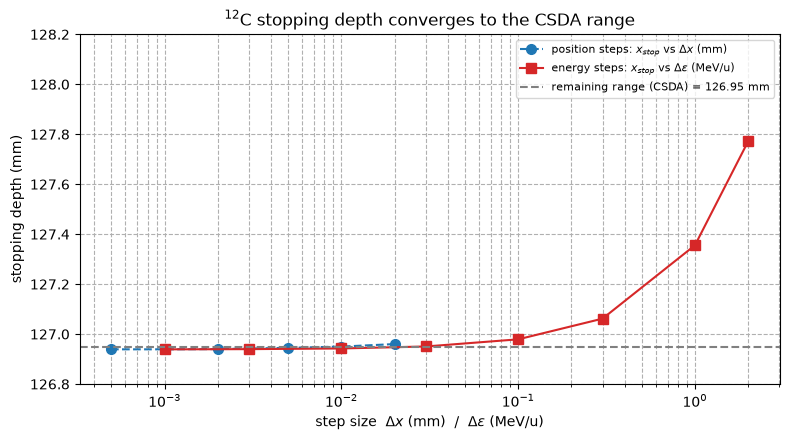

In [12]:
# ================= 4.3 补充：停止深度随步长减小而收敛 =================
# 逐步减小步长，看两种逐步积分的停止深度是否趋近剩余射程法（CSDA）的结果。
# 注意：cell 3 / cell 9 里有 `if len(...) > 50000: break` 的点数上限，
# dx <= 0.002 mm 时位置步长法还没走到 127 mm 就会被这个上限截断，
# 所以这里用同样的积分公式、仅去掉该上限，才能看出真实的收敛趋势。
import matplotlib.pyplot as plt

def fixed_x_stop(eps0, A, S_func, dx):
    x, E = 0.0, A * eps0
    while E > 0:
        eps = E / A
        S = S_func(eps)
        if not np.isfinite(S):
            break
        if S * dx > E:
            break
        x += dx
        E -= S * dx
    return x

def fixed_E_stop(eps0, A, S_func, d_eps):
    x, eps = 0.0, eps0
    while eps > 0:
        S = S_func(eps)
        if not np.isfinite(S):
            break
        step = min(d_eps, eps)
        x += A * step / S
        eps -= step
    return x

DX_LIST   = [0.02, 0.01, 0.005, 0.002, 0.001, 0.0005]                 # mm
DEPS_LIST = [2.0, 1.0, 0.3, 0.1, 0.03, 0.01, 0.003, 0.001]            # MeV/u

stop_dx = [fixed_x_stop(eps0_C, A_C, S_of_eps_C, dx)   for dx in DX_LIST]
stop_de = [fixed_E_stop(eps0_C, A_C, S_of_eps_C, deps) for deps in DEPS_LIST]

print("  位置步长法 x_stop: " + ", ".join(f"{dx:g}->{s:.4f}" for dx, s in zip(DX_LIST, stop_dx)))
print("  能量步长法 x_stop: " + ", ".join(f"{d:g}->{s:.4f}" for d, s in zip(DEPS_LIST, stop_de)))
print(f"  剩余射程法(CSDA): {R_target:.4f} mm")

fig_conv, ax_conv = plt.subplots(figsize=(8, 4.5))
ax_conv.semilogx(DX_LIST,   stop_dx, 'o--', color='tab:blue', markersize=7,
                 label=r'position steps: $x_{stop}$ vs $\Delta x$ (mm)')
ax_conv.semilogx(DEPS_LIST, stop_de, 's-',  color='tab:red',  markersize=7,
                 label=r'energy steps: $x_{stop}$ vs $\Delta\varepsilon$ (MeV/u)')
ax_conv.axhline(R_target, color='gray', linestyle='--', linewidth=1.5,
                label=f'remaining range (CSDA) = {R_target:.2f} mm')
ax_conv.set_xlabel(r'step size  $\Delta x$ (mm)  /  $\Delta\varepsilon$ (MeV/u)')
ax_conv.set_ylabel('stopping depth (mm)')
ax_conv.set_title(r'$^{12}$C stopping depth converges to the CSDA range')
ax_conv.set_ylim(126.8, 128.2)
ax_conv.legend(fontsize=8)
ax_conv.grid(True, which="both", ls="--")
fig_conv.tight_layout()
plt.show()

In [14]:
!jupyter nbconvert --to html homework1.1.ipynb

SyntaxError: invalid syntax (630874266.py, line 1)